# Tarea1 - deep learning

## 1. Descripción

La rodilla es la parte de la pierna que mas se lesiona y que las resonancias magnéticas permiten a los médicos visualizar con detalle los ligamentos, el cartílago, los meniscos y el hueso, sin exponer a los pacientes a la radiación.

La interpretación de estas imágenes no siempre es sencilla como: las roturas de ligamentos cruzados, lesiones meniscales, pérdida de cartílago, fracturas y otras anomalías pueden ser sutiles, y los radiólogos no siempre las interpretan de la misma manera. Lo que provoca retrasos y diagnósticos inconsistentes.

Este proyecto consta en detectar doce anomalías de rodilla clínicamente relevantes. trabajaremos en cada estudio de imagen con su informe radiológico original, lo que permitira que nuestro modelo aprenda tanto de las imágenes como del texto diagnóstico escrito.

Con el objetivo de una ayuda preliminar en la deteccion de estas lesiones de rodilla.

## 2. Datos

Este conjunto de datos contiene estudios de resonancia magnética de rodilla anotados para doce hallazgos comunes: lesiones de ligamentos y meniscos, tres compartimentos de osteoartritis, derrame articular, sinovitis, quiste de Baker, contusión ósea y fractura. Cada estudio comprende una colección de secuencias de resonancia magnética individuales de una única sesión de escaneo, formateadas como series DICOM.

2.1 train.csv

* StudyInstanceUID -  identificador único para el estudio; coincide con el nombre de la carpeta en train_series/.
* Report - El informe radiológico en texto libre. Puede estar en varios idiomas, según la institución que lo emita.

Las 12 etiquetas binarias:

* ACL - Lesión del ligamento cruzado anterior (0/1).
* MCL - lesión del ligamento colateral medial (0/1).
* Medial Meniscus - Desgarro del menisco medial (0/1).
* Lateral Meniscus - Desgarro del menisco lateral (0/1).
* Medial OA - Osteoartritis del compartimento tibiofemoral medial (0/1).
* Lateral OA - Artrosis del compartimento tibiofemoral lateral (0/1).
* PF OA - Osteoartritis patelofemoral (0/1).
* Effusion - Derrame articular / exceso de líquido (0/1).
* Synovitis - Inflamación del revestimiento articular (0/1).
* Baker's - Quiste de Baker (0/1).
* Contusion - Contusión ósea / hematoma óseo (0/1).
* Fracture - Fractura (0/1).

2.2 series_train.csv

Una fila por serie de entrenamiento. Cada serie es una única adquisición de resonancia magnética y cada estudio comprende varias series.

* StudyInstanceUID - Estudio al que pertenece esta serie.
* SeriesInstanceUID - Identificador único para la serie; coincide con el nombre de la carpeta en train_series.
* Fluid_Sensitive - 1 Si la secuencia enfatiza la señal de fluidos (T2, PD, STIR y similares), 0 de lo contrario.
* Fat_Suppression - 1 Si la secuencia aplica supresión de grasa, 0de lo contrario. Tenga en cuenta que, si bien Fluid_Sensitivey Fat_Suppression suelen estar correlacionados, como se observa en el conjunto de entrenamiento, no son necesariamente equivalentes en todos los casos.
* Anatomical_Plane - Plano de imagen: Sagittal, Coronal, o Axial.

## COMO TRABAJAREMOS PARA COMPLETAR LOS LABELS DE TRAIN Y ELEGIR QUE  TIPO PERFIL DE IMAGEN A USAR PARA CNN

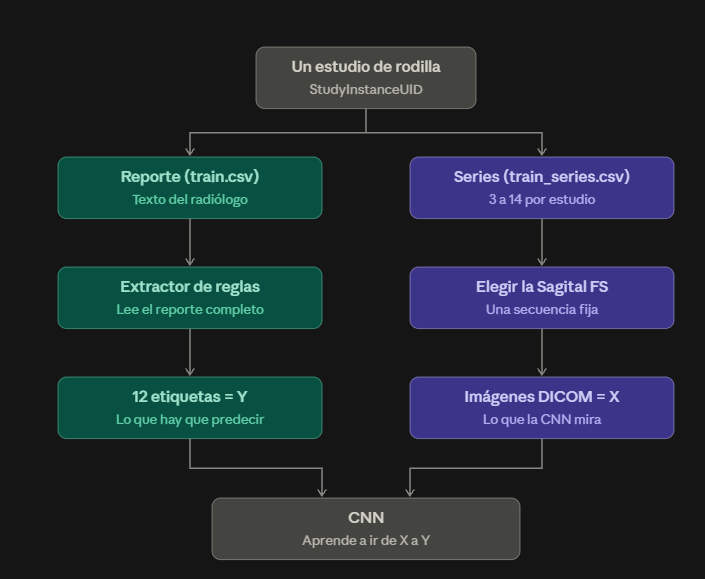

In [ ]:
import os
import re
import sys
import time
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Montar directorio del google drive
from google.colab import drive
drive.mount('/content/drive')
path = '/content/drive/MyDrive/MAESTRIA IA - UNI/DEEP LEARNING/rodilla/'
sys.path.append(path)          # para importar extractor.py (Paso 7)
os.listdir(path)

Mounted at /content/drive


['data',
 'extractor.py',
 'clean',
 '__pycache__',
 'muestra_series_100.csv',
 'muestra_train_100.csv',
 'rodilla.ipynb']

## PASO 1 : ENTENDIENDO LOS DATOS

In [ ]:
train = pd.read_csv(path + "/data/train.csv")
series = pd.read_csv(path + "/data/train_series.csv")

print("train:", train.shape)
print("series:", series.shape)
print("\n Columnas de train:\n", list(train.columns))
print("\n Columnas de columnas:\n", list(series.columns))

train: (4407, 14)
series: (24371, 5)

 Columnas de train:
 ['StudyInstanceUID', 'Report', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']

 Columnas de columnas:
 ['StudyInstanceUID', 'SeriesInstanceUID', 'Fluid_Sensitive', 'Fat_Suppression', 'Anatomical_Plane']


In [ ]:
print("TRAIN:\n", train.head())

TRAIN:
                                     StudyInstanceUID  \
0  1.2.826.0.1.3680043.8.498.10004873229099053869...   
1  1.2.826.0.1.3680043.8.498.10004945927472656027...   
2  1.2.826.0.1.3680043.8.498.10009278692606631573...   
3  1.2.826.0.1.3680043.8.498.10009639203170750274...   
4  1.2.826.0.1.3680043.8.498.10013663742400736029...   

                                              Report  ACL  MCL  \
0  Técnica: RMN de la rodilla. Resultados: Rotura...  NaN  NaN   
1  [DATE]: * MR Knie Rechts 15ch AA Klinische Inl...  NaN  NaN   
2  Hallazgos:\nNo hay alteraciones en significati...  NaN  NaN   
3   In the medial compartment, the meniscus is no...  NaN  NaN   
4  CONSTATATIONS :\n\nFractures :\nAucune.\n\nAli...  NaN  NaN   

   Medial Meniscus  Lateral Meniscus  Medial OA  Lateral OA  PF OA  Effusion  \
0              NaN               NaN        NaN         NaN    NaN       NaN   
1              NaN               NaN        NaN         NaN    NaN       NaN   
2              NaN

In [ ]:
print("TRAIN SERIES:\n", series.head())

TRAIN SERIES:
                                     StudyInstanceUID  \
0  1.2.826.0.1.3680043.8.498.10004873229099053869...   
1  1.2.826.0.1.3680043.8.498.10004873229099053869...   
2  1.2.826.0.1.3680043.8.498.10004873229099053869...   
3  1.2.826.0.1.3680043.8.498.10004873229099053869...   
4  1.2.826.0.1.3680043.8.498.10004873229099053869...   

                                   SeriesInstanceUID  Fluid_Sensitive  \
0  1.2.826.0.1.3680043.8.498.12343110195036213483...                1   
1  1.2.826.0.1.3680043.8.498.13821229744997220641...                1   
2  1.2.826.0.1.3680043.8.498.23084836536722595275...                0   
3  1.2.826.0.1.3680043.8.498.40734206102458723096...                1   
4  1.2.826.0.1.3680043.8.498.75714899997203615784...                0   

   Fat_Suppression Anatomical_Plane  
0                1         Sagittal  
1                1            Axial  
2                0          Coronal  
3                1          Coronal  
4                0 

## ENTENDIENDO LAS ETIQUETAS/TARGETS

In [ ]:
# Paso 1 — IDs únicos y todo estudio tiene series (y viceversa)
assert train["StudyInstanceUID"].is_unique and series["SeriesInstanceUID"].is_unique
assert set(train["StudyInstanceUID"]) == set(series["StudyInstanceUID"])
print("IDs únicos y conjuntos de estudios iguales en train y series ✔")

IDs únicos y conjuntos de estudios iguales en train y series ✔


In [ ]:
LABELS = ["ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
          "Medial OA", "Lateral OA", "PF OA", "Effusion",
          "Synovitis", "Baker's", "Contusion", "Fracture"]
assert all(c in train.columns for c in LABELS)

In [ ]:
for c in LABELS:
    print(f"{c:18s}", train[c].value_counts(dropna=False).to_dict())

ACL                {nan: 4349, 0.0: 34, 1.0: 24}
MCL                {nan: 4349, 0.0: 49, 1.0: 9}
Medial Meniscus    {nan: 4349, 0.0: 32, 1.0: 26}
Lateral Meniscus   {nan: 4349, 0.0: 35, 1.0: 23}
Medial OA          {nan: 4349, 0.0: 43, 1.0: 15}
Lateral OA         {nan: 4349, 0.0: 47, 1.0: 11}
PF OA              {nan: 4349, 0.0: 37, 1.0: 21}
Effusion           {nan: 4349, 1.0: 35, 0.0: 23}
Synovitis          {nan: 4349, 0.0: 31, 1.0: 27}
Baker's            {nan: 4349, 0.0: 46, 1.0: 12}
Contusion          {nan: 4349, 0.0: 39, 1.0: 19}
Fracture           {nan: 4349, 0.0: 40, 1.0: 18}


0     4349
12      58
Name: count, dtype: int64


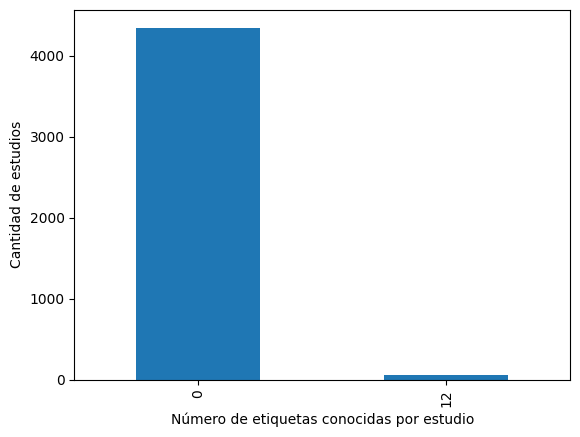

In [ ]:
n_etiquetas = train[LABELS].notna().sum(axis=1)
print(n_etiquetas.value_counts().sort_index())

n_etiquetas.value_counts().sort_index().plot(kind="bar")
plt.xlabel("Número de etiquetas conocidas por estudio")
plt.ylabel("Cantidad de estudios")
plt.show()

Traduccion: Se entiende que de 58 estudios conocemos 12 etiquetas, y 4349 estudios que no nococemos nada.

Entonces tenemos que encontrar esas etiquetas a partir de su reporte

Estudios gold: 58
                  positivos  %_aparicion
MCL                       9         15.5
Lateral OA               11         19.0
Baker's                  12         20.7
Medial OA                15         25.9
Fracture                 18         31.0
Contusion                19         32.8
PF OA                    21         36.2
Lateral Meniscus         23         39.7
ACL                      24         41.4
Medial Meniscus          26         44.8
Synovitis                27         46.6
Effusion                 35         60.3


Text(0.5, 1.0, 'Porcentaje de aparicion (gold)')

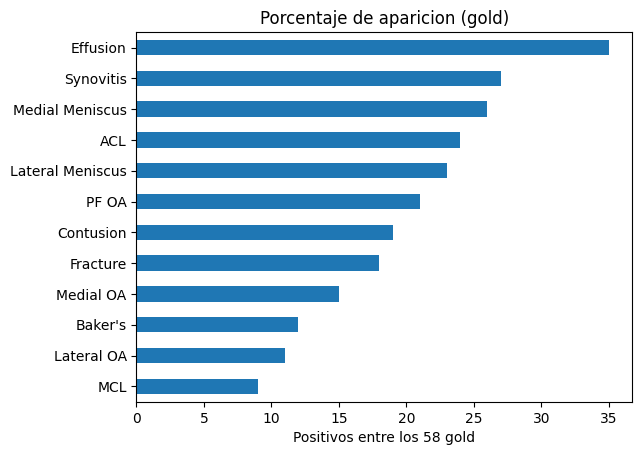

In [ ]:
#  Prevalencia en los 58 gold
gold = train[n_etiquetas == 12].copy()
print("Estudios gold:", len(gold))

prev = pd.DataFrame({
    "positivos": gold[LABELS].sum().astype(int),
    "%_aparicion": (gold[LABELS].mean() * 100).round(1)
}).sort_values("positivos")
print(prev)

prev["positivos"].plot(kind="barh", color="tab:blue")
plt.xlabel("Positivos entre los 58 gold")
plt.title("Porcentaje de aparicion (gold)")

Notamos que Effucion es la lesion que mas se repite, y que el MCL es la lesion menos frecuente

## ANALISIS DEL REPORTE

PASO 3.1 — Longitud de los reportes
count    4407.0
mean      147.5
std        95.3
min         8.0
25%        74.5
50%       129.0
75%       202.0
max       690.0
Name: n_palabras, dtype: float64

Mediana de palabras (gold vs no-gold):
es_gold
False    128.0
True     161.5
Name: n_palabras, dtype: float64

Reportes con menos de 15 palabras: 39
  [11 palabras] 'Técnica: RMN de la rodilla. Resultados: Sin anomalías. Impresión: Sin anomalías'
  [11 palabras] 'Técnica: RMN de la rodilla. Resultados: Sin anomalías. Impresión: Sin anomalías'
  [13 palabras] 'Técnica: RMN de la rodilla. Resultados: OA patelofemoral moderada. Impresión: OA patelofemoral moderada.'
  [12 palabras] 'Técnica: RMN de la rodilla. Resultados: Sin anomalías. . Impresión: Sin anomalías.'
  [13 palabras] 'Técnica: RMN de la rodilla. Resultados: OA patelofemoral moderada. Impresión: OA patelofemoral moderada.'


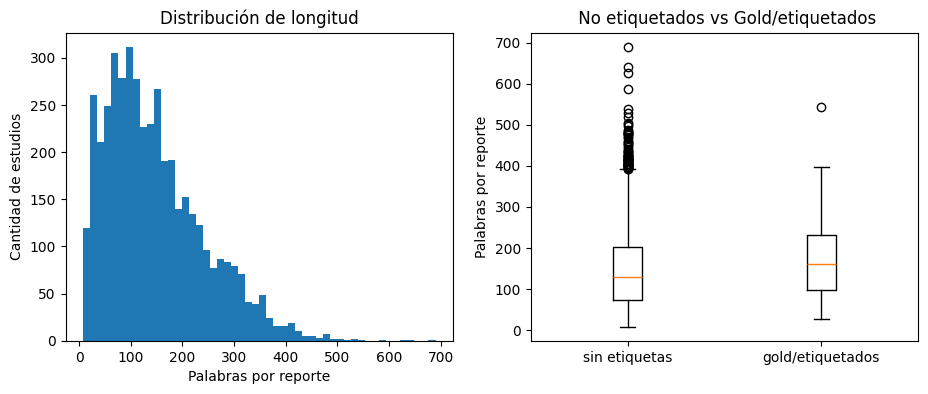

In [ ]:
# %% Paso 3.1 — Longitud de los reportes (en palabras)
print("PASO 3.1 — Longitud de los reportes")
train["n_palabras"] = train["Report"].str.split().str.len()
train["es_gold"] = n_etiquetas == 12

print(train["n_palabras"].describe().round(1))
print("\nMediana de palabras (gold vs no-gold):")
print(train.groupby("es_gold")["n_palabras"].median())

cortos = train[train["n_palabras"] < 15]
print(f"\nReportes con menos de 15 palabras: {len(cortos)}")
for _, r in cortos.head(5).iterrows():
    print(f"  [{r['n_palabras']} palabras] {r['Report'][:150]!r}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(train["n_palabras"], bins=50)
ax[0].set_xlabel("Palabras por reporte")
ax[0].set_ylabel("Cantidad de estudios")
ax[0].set_title("Distribución de longitud")
ax[1].boxplot([train.loc[~train["es_gold"], "n_palabras"],
               train.loc[train["es_gold"], "n_palabras"]])
ax[1].set_xticks([1, 2], ["sin etiquetas", "gold/etiquetados"])
ax[1].set_ylabel("Palabras por reporte")
ax[1].set_title(" No etiquetados vs Gold/etiquetados")
plt.show()

* Cada barra nos dice cuantas palabras hay en cada reporte; por tanto, notamos que la mayoria esta entre 50 y 200 palabras con un pico de 100.
* En los boxplots notamos que hay en que la mayoria de palabras en ambos boxplots estan tambien entre 50 y 100, ambos grupos con la misma distribucion de los datos.

In [ ]:
# libreria para la deteccion del  idioma de texto
!pip install langdetect

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 16.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for langdetect: filename=langdetect-1.0.9-py3-none-any.whl size=993223 sha256=3a4eaa5a071bc376ab6859470677f8453dfe0914b65925514d8ff8016fec9b16
  Stored in directory: /root/.cache/pip/wheels/c1/67/88/e844b5b022812e15a52e4eaa38a1e709e99f06f6639d7e3ba7
Successfully built langdetect


idioma
en    1736
es     682
tr     546
hr     406
el     321
de     262
bg     220
nl     153
fr      81
Name: count, dtype: int64


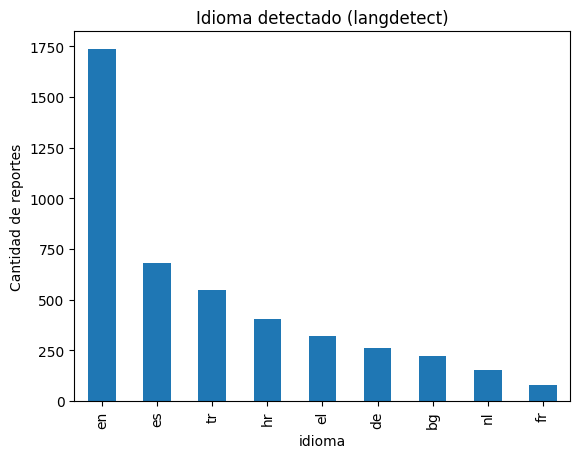

In [ ]:
from langdetect import detect, DetectorFactory
DetectorFactory.seed = 0   # langdetect es aleatorio; la semilla lo hace reproducible


def idioma(texto):
    try:
        return detect(texto)
    except Exception:
        return "desconocido"

cache_idioma = path + "/data/idioma_cache.csv"
if os.path.exists(cache_idioma):
    train = train.merge(pd.read_csv(cache_idioma), on="StudyInstanceUID", how="left")
else:
    train["idioma"] = train["Report"].apply(idioma)
    train[["StudyInstanceUID", "idioma"]].to_csv(cache_idioma, index=False)

conteo_idioma = train["idioma"].value_counts()
print(conteo_idioma)

conteo_idioma.plot(kind="bar")
plt.ylabel("Cantidad de reportes")
plt.title("Idioma detectado (langdetect)")
plt.show()

* hemos detectado 9 idiomas en el reporte.
* la mayoria de las muestra estan en ingles
* la menor cantidad esta en frances.


Glosario:
| Código | Idioma                     |
| ------ | -------------------------- |
| **en** | 🇬🇧 Inglés                |
| **es** | 🇪🇸 Español               |
| **tr** | 🇹🇷 Turco                 |
| **hr** | 🇭🇷 Croata                |
| **el** | 🇬🇷 Griego                |
| **de** | 🇩🇪 Alemán                |
| **bg** | 🇧🇬 Búlgaro               |
| **nl** | 🇳🇱 Neerlandés / Holandés |
| **fr** | 🇫🇷 Francés               |


        no_gold  gold  total  %_del_idioma_en_gold
idioma                                            
en         1708    28   1736                  1.61
es          672    10    682                  1.47
tr          540     6    546                  1.10
hr          402     4    406                  0.99
el          318     3    321                  0.93
de          260     2    262                  0.76
bg          217     3    220                  1.36
nl          151     2    153                  1.31
fr           81     0     81                  0.00
Idiomas SIN ningún gold: ['fr']


Text(0.5, 1.0, 'Estudios gold (58)')

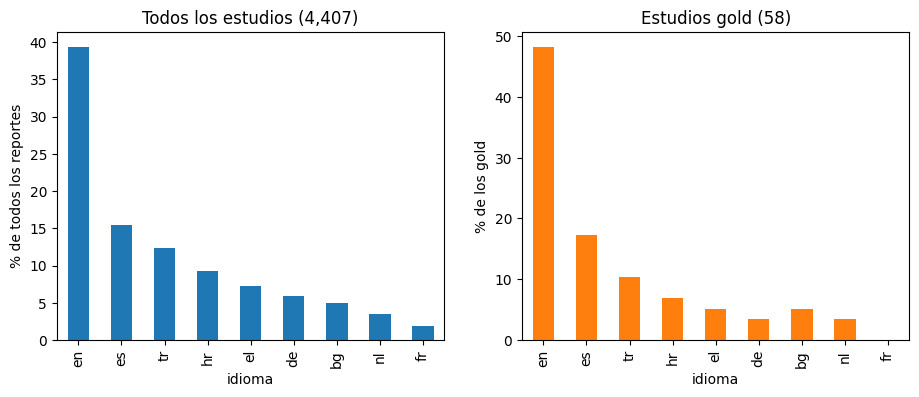

In [ ]:
tabla = pd.crosstab(train["idioma"], train["es_gold"])
tabla.columns = ["no_gold", "gold"]
tabla["total"] = tabla.sum(axis=1)
tabla["%_del_idioma_en_gold"] = (tabla["gold"] / tabla["total"] * 100).round(2)
tabla = tabla.sort_values("total", ascending=False)
print(tabla)
print("Idiomas SIN ningún gold:", list(tabla.index[tabla["gold"] == 0]))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
(tabla["total"] / tabla["total"].sum() * 100).plot(kind="bar", ax=ax[0])
ax[0].set_ylabel("% de todos los reportes")
ax[0].set_title("Todos los estudios (4,407)")
(tabla["gold"] / tabla["gold"].sum() * 100).plot(kind="bar", ax=ax[1], color="tab:orange")
ax[1].set_ylabel("% de los gold")
ax[1].set_title("Estudios gold (58)")

Aca notamos que la distribucion en el grupo de gold(muestras etiquetadas) tienen la similitud en la distribucion de idiomas con respecto a todas las muestras.



In [ ]:
train.columns

Index(['StudyInstanceUID', 'Report', 'ACL', 'MCL', 'Medial Meniscus',
       'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion',
       'Synovitis', 'Baker's', 'Contusion', 'Fracture', 'n_palabras',
       'es_gold', 'idioma'],
      dtype='object')

In [ ]:
griego = train.loc[train["idioma"] == "el", ["Report"]]
griego.sample(5)

,Report
2890,ΤΕΧΝΙΚΗ: Η εξέταση έγινε σε Τοµογράφο 3Τ µε ακ...
1535,ΤΕΧΝΙΚΗ: Η εξέταση πραγµατοποιήθηκε µε ακολουθ...
2901,ΜΑΓΝΗΤΙΚΗ ΤΟΜΟΓΡΑΦΙΑ ∆ΕΞΙΟΥ ΓΟΝΑΤΟΣ TEXNIKH: Η...
3381,ΤΕΧΝΙΚΗ Η εξέταση έγινε µε ακολουθίες παλµών Τ...
1064,ΤΕΧΝΙΚΗ: Η εξέταση πραγµατοποιήθηκε µε ακολουθ...


In [ ]:
# %% Normalización NFKC: µ (U+00B5, micro) -> μ (U+03BC, griega), NBSP -> espacio
MICRO = "\u00b5"
train["Report_norm"] = train["Report"].apply(lambda t: unicodedata.normalize("NFKC", t))
# %% Lo que NFKC no arregla: ∆ (signo matemático) y restos de RTF
DELTA_MAT, DELTA = "\u2206", "\u0394"   # ∆ "incremento" vs Δ griega: se ven iguales, NFKC no los une
# RTF (formato de Word) dejó escapes en algunos reportes holandeses:
#   \'e0 = byte 0xE0 en Windows-1252 = "à"  ("graad 2 \'e0 3" = "grado 2 a 3"),  \'b0 = "°"
#   \~   = espacio de no separación de RTF  ("12\~mm" = "12 mm")
PATRON_RTF_HEX = re.compile(r"\\'([0-9a-fA-F]{2})")

In [ ]:
def limpiar_extra(texto):
    texto = texto.replace(DELTA_MAT, DELTA)
    texto = PATRON_RTF_HEX.sub(lambda m: bytes.fromhex(m.group(1)).decode("cp1252"), texto)
    return texto.replace("\\~", " ")


train["Report_norm"] = train["Report_norm"].apply(limpiar_extra)
assert not train["Report_norm"].str.contains(MICRO).any()
assert not train["Report_norm"].str.contains(DELTA_MAT).any()
assert not train["Report_norm"].str.contains("\\", regex=False).any()
print("Report_norm sin µ, sin ∆ y sin restos de RTF ✔")

Report_norm sin µ, sin ∆ y sin restos de RTF ✔


In [ ]:
train.sample(5)

,StudyInstanceUID,Report,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture,n_palabras,es_gold,idioma,Report_norm
4219,1.2.826.0.1.3680043.8.498.95193282490279394602...,Técnica: RMN de la rodilla. Resultados: Síndro...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,25,False,es,Técnica: RMN de la rodilla. Resultados: Síndro...
1669,1.2.826.0.1.3680043.8.498.26512333939158074470...,Exam Type: MRI KNEE LEFT WO CONTRAST\nExam Dat...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,310,False,en,Exam Type: MRI KNEE LEFT WO CONTRAST\nExam Dat...
2108,1.2.826.0.1.3680043.8.498.38010459551726691601...,Findings: No evidence of knee effusion. Norma...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,72,False,en,Findings: No evidence of knee effusion. Norma...
2902,1.2.826.0.1.3680043.8.498.59954207362160100069...,[DATE]: MR Knie Links 15ch AA: Klinische inlic...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,237,False,nl,[DATE]: MR Knie Links 15ch AA: Klinische inlic...
3944,1.2.826.0.1.3680043.8.498.87761573479019057997...,Exam Type: MRI KNEE RIGHT WO CONTRAST\nExam Da...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,327,False,en,Exam Type: MRI KNEE RIGHT WO CONTRAST\nExam Da...


In [ ]:
#Poner aqui codigo para ver el reto del extractor
# como Negaciones, una negacion para varias etiquetas, sinonimos, grados , etc con sus respectivos ejemplos
#

## ANALISIS DEL TRAIN SERIES



PASO 4.3 — Cobertura por combinación

               todos_%  gold_%
Axial FS         100.0   100.0
Sagittal noFS     96.8    98.3
Coronal FS        96.4    96.6
Sagittal FS       94.2    96.6
Coronal noFS      77.3    77.6
Axial noFS        19.4    22.4


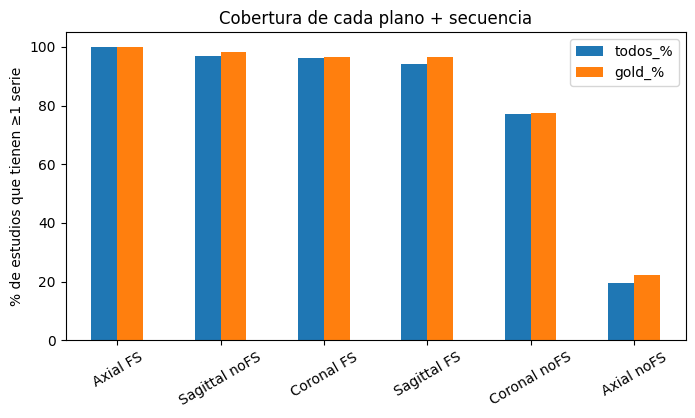

In [ ]:
print("PASO 4.3 — Cobertura por combinación\n")
# Fluid_Sensitive y Fat_Suppression son la misma variable (crosstab diagonal): basta una para el combo
assert (series["Fluid_Sensitive"] == series["Fat_Suppression"]).all()
series["combo"] = series["Anatomical_Plane"] + np.where(series["Fluid_Sensitive"] == 1, " FS", " noFS")
n_combo = series.pivot_table(index="StudyInstanceUID", columns="combo",
                             values="SeriesInstanceUID", aggfunc="count", fill_value=0)
train = train.merge(n_combo, left_on="StudyInstanceUID", right_index=True, how="left")

cobertura = pd.DataFrame({
    "todos_%": ((train[n_combo.columns] > 0).mean() * 100).round(1),
    "gold_%": ((train.loc[train["es_gold"], n_combo.columns] > 0).mean() * 100).round(1),
}).sort_values("todos_%", ascending=False)
print(cobertura)

cobertura.plot(kind="bar", figsize=(8, 4))
plt.ylabel("% de estudios que tienen ≥1 serie")
plt.ylim(0, 105)
plt.xticks(rotation=30)
plt.title("Cobertura de cada plano + secuencia")
plt.show()

* **Axial FS**, es la unica al 100%, secuencia que todos los centros hacen, el axial es el mejor plano para la rotula no para LCA y meniscos, que son las etiquetas mas frecuentes.
* **Las 4 primeras**, rondan el 95-100 % asi que cualquiera es viable.
* **Coronal noFS y Axial noFS no son viable** perderiamos el 23 y80 % de los estudios.
* **Sagital FS es la de menor cobertura**, y es la que elegiremos porque muestra el LCA es toda su longitud, los meniscales, el derrame en el receso suprapatelar, el baker y el edema oseo. Es decir, la mayoria de las 12 etiquetas. El 96% de los gold son los 56 de 58 que usaremos en la evaluacion.


## ESTUDIO: SAGITAL FS o CORONAL




Sagital FS por estudio

Sagittal FS
0     257
1    3639
2     505
3       6
Name: count, dtype: int64

Gold:
Sagittal FS
0     2
1    48
2     8
Name: count, dtype: int64

Cobertura por idioma (% de estudios con ≥1 serie):
        Sagittal FS  Coronal FS  Axial FS  Sagittal noFS
idioma                                                  
bg            100.0       100.0     100.0           99.1
de              6.5       100.0     100.0          100.0
el             98.1        99.4     100.0           70.1
en             99.7        91.1     100.0           99.3
es             99.9       100.0     100.0           99.7
fr            100.0       100.0     100.0          100.0
hr            100.0       100.0     100.0          100.0
nl            100.0        99.3     100.0          100.0
tr            100.0        99.6     100.0           94.7


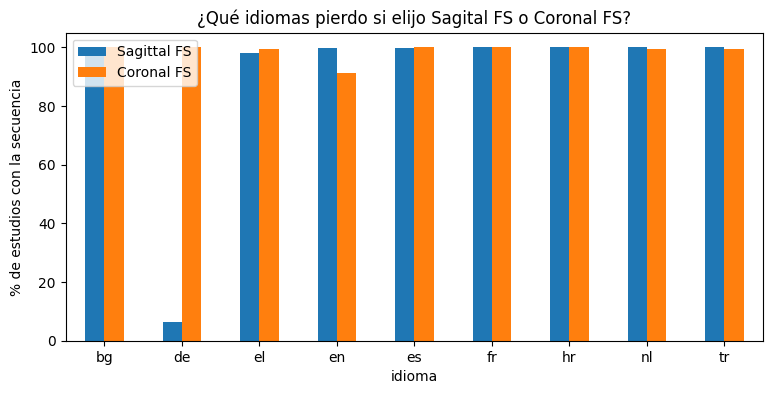

In [ ]:
print("Sagital FS por estudio\n")
print(train["Sagittal FS"].value_counts().sort_index())
print("\nGold:")
print(train.loc[train["es_gold"], "Sagittal FS"].value_counts().sort_index())

# ¿La secuencia elegida existe en todos los centros/idiomas? Si no, excluirla sesga la muestra.
cob_idioma = pd.DataFrame({
    c: train.groupby("idioma")[c].apply(lambda s: (s > 0).mean() * 100)
    for c in ["Sagittal FS", "Coronal FS", "Axial FS", "Sagittal noFS"]
}).round(1)
print("\nCobertura por idioma (% de estudios con ≥1 serie):")
print(cob_idioma)

cob_idioma[["Sagittal FS", "Coronal FS"]].plot(kind="bar", figsize=(9, 4))
plt.ylabel("% de estudios con la secuencia")
plt.ylim(0, 105)
plt.xticks(rotation=0)
plt.title("¿Qué idiomas pierdo si elijo Sagital FS o Coronal FS?")
plt.show()

CUANTA SAGITAL FS HAY POR ESTUDIO

* La columna Sagital FS lo llevamos a train y hacemos el conteo de series de ese tipo por estudio y contamos cuantos estudios tienen 0, 1, 2, 3.

* 0 -> 257 estudios, que  no podremos usar, y entre ellos 2 de gold, por eso evaluaremos sobre los 56 y no sobre los 58.
* 2 o 3 -> 511 estudios, con mas de una cantidata, entonces habria equue elegir una regla mejor.

CUANTA COBERTURA POR IDIOMA

* La barra azul *de* se desploma, los centros alemanes casi nunca hacen Sagital FS.
* las cuentas cuadran, dee 262 estudios alemanes solo 17 tienen sagital quedan escluidos el 95%
* el coronal FS tenia un problema contrario cubre el aleman pero pierde el 9% del ingles(150 estudios) que es el idioma mas grande.


CONCLUSION:

etiquetas que se ven bien:
* SAGITAL: ACL, meniscos,derrame,Baker, contusion, PF parcial.
* Coronal: MCL, meniscos, OA media/lateral.

a quien excluye:
* Aleman casi entero
* 9% del ingles

-> El Sagital FS cubre mas etiquetas y las mas frecuentes. pero el modelo nunca vera un centro aleman al entrenar. Esto entra en la discusion para sesgo linguistico o geografico y Coronal FS queda como factor de ablacion lo que  permite medir cuanto cambia el resultado.

Estudios elegibles (con ≥1 Sagital FS)

        total  elegibles  gold_elegibles  excluidos  %_elegible
idioma                                                         
en       1736       1731              28          5        99.7
es        682        681              10          1        99.9
tr        546        546               6          0       100.0
hr        406        406               4          0       100.0
el        321        315               3          6        98.1
de        262         17               0        245         6.5
bg        220        220               3          0       100.0
nl        153        153               2          0       100.0
fr         81         81               0          0       100.0

Elegibles: 4150 de 4407  |  gold elegibles: 56 de 58
Gold excluidos:
                                       StudyInstanceUID idioma
3425  1.2.826.0.1.3680043.8.498.73926443729786165628...     de
4302  1.2.826.0.1.3680043.8.498.97274720257634584071...     

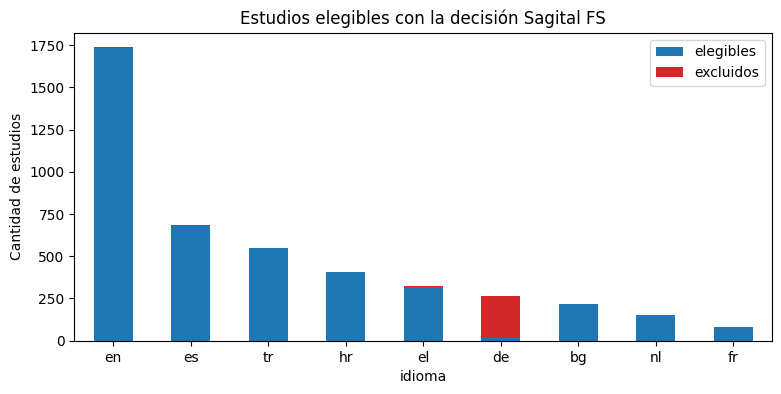

In [ ]:
print("Estudios elegibles (con ≥1 Sagital FS)\n")
train["elegible"] = train["Sagittal FS"] > 0

eleg = train.groupby("idioma").agg(
    total=("elegible", "size"),
    elegibles=("elegible", "sum"),
    gold_elegibles=("es_gold", lambda s: (s & train.loc[s.index, "elegible"]).sum()),
)
eleg["excluidos"] = eleg["total"] - eleg["elegibles"]
eleg["%_elegible"] = (eleg["elegibles"] / eleg["total"] * 100).round(1)
eleg = eleg.sort_values("total", ascending=False)
print(eleg)
print(f"\nElegibles: {train['elegible'].sum()} de {len(train)}  |  "
      f"gold elegibles: {(train['elegible'] & train['es_gold']).sum()} de 58")
print("Gold excluidos:")
print(train.loc[train["es_gold"] & ~train["elegible"], ["StudyInstanceUID", "idioma"]])

eleg[["elegibles", "excluidos"]].plot(kind="bar", stacked=True, figsize=(9, 4),
                                      color=["tab:blue", "tab:red"])
plt.ylabel("Cantidad de estudios")
plt.xticks(rotation=0)
plt.title("Estudios elegibles con la decisión Sagital FS")
plt.show()

# PROBAMOS EL EXTRACTOR PARA MEDIR SI LEEMOS BIEN LOS REPORTES
(anotar como se escriben los sinimos, negaciones, grados) pero lo haremos con una muestra real de 100 antes de pasar los 4000 restantes

Muestra de 100 estudios

Cuota por idioma:
idioma
en    33
es    16
tr    13
hr    10
el     8
bg     5
nl     5
fr     5
de     5
Name: proportion, dtype: int64
Tamaño de la muestra: 100


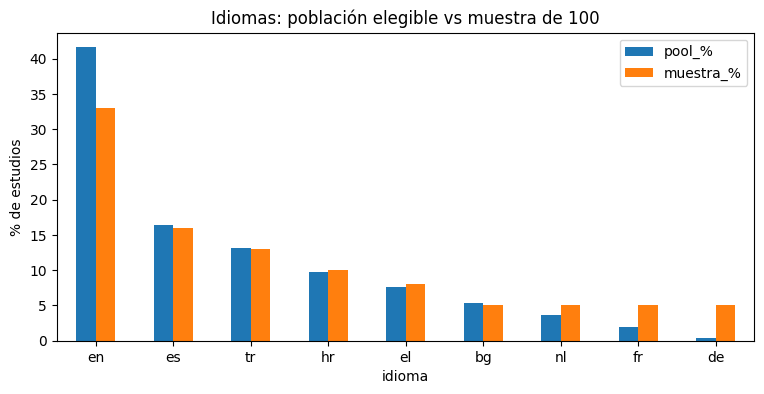

Guardado: muestra_train_100.csv (100 filas), muestra_series_100.csv (567 filas)


In [ ]:
print("Muestra de 100 estudios\n")
# Solo elegibles y NO gold: los gold no se usan para diseñar el extractor (evita fuga de información).
# Estratificada por idioma: proporcional, pero con mínimo 5 por idioma para poder leer todos.
pool = train[train["elegible"] & ~train["es_gold"]]
N_MUESTRA, MINIMO = 100, 5

cuota = (pool["idioma"].value_counts(normalize=True) * N_MUESTRA).round().astype(int).clip(lower=MINIMO)
while cuota.sum() > N_MUESTRA:          # el mínimo puede pasarse de 100: se recorta al idioma más grande
    cuota[cuota.idxmax()] -= 1
cuota = cuota.clip(upper=pool["idioma"].value_counts())   # no pedir más de los que hay

muestra = pd.concat([
    pool[pool["idioma"] == lang].sample(n, random_state=42) for lang, n in cuota.items()
])
print("Cuota por idioma:")
print(cuota)
print("Tamaño de la muestra:", len(muestra))

comparar = pd.DataFrame({
    "pool_%": (pool["idioma"].value_counts(normalize=True) * 100).round(1),
    "muestra_%": (muestra["idioma"].value_counts(normalize=True) * 100).round(1),
})
comparar.plot(kind="bar", figsize=(9, 4))
plt.ylabel("% de estudios")
plt.xticks(rotation=0)
plt.title("Idiomas: población elegible vs muestra de 100")
plt.show()

cols_muestra = ["StudyInstanceUID", "idioma", "n_palabras", "Sagittal FS", "Report_norm"]
muestra[cols_muestra].to_csv(path +  "/muestra_train_100.csv", index=False)
muestra_series = series[series["StudyInstanceUID"].isin(muestra["StudyInstanceUID"])]
muestra_series.to_csv(path +  "/muestra_series_100.csv", index=False)
print(f"Guardado: muestra_train_100.csv ({len(muestra)} filas), "
      f"muestra_series_100.csv ({len(muestra_series)} filas)")

hay dos filtros:
- Elegible, no tiene sentido diseñar reglas con estudios que no vamos a usar
- No gold, la idea de fuga de informacion, los golds son nuestro examen final para el extractor, para validar los resultados.

pool: 4150 elegibles,  56 golds = 4094 estudios.

La imagen:
- el azul = % en la poblacion elegible, naranja = % en la muestra.
vemos un sobremuestreo intencional para cubrir la variedad linguistica para diseñar.

In [ ]:
print("Tablas limpias\n")
CLEAN = os.path.join(path, "clean")
os.makedirs(CLEAN, exist_ok=True)

cols_train = ["StudyInstanceUID", "idioma", "es_gold", "elegible", "n_palabras", "Report_norm"] + LABELS + list(n_combo.columns)
train_clean = train[cols_train].copy()

series_clean = series.merge(train[["StudyInstanceUID", "idioma", "es_gold"]], on="StudyInstanceUID")
series_clean["es_sagital_fs"] = series_clean["combo"] == "Sagittal FS"

train_clean.to_parquet(os.path.join(CLEAN, "train_clean.parquet"), index=False)
series_clean.to_parquet(os.path.join(CLEAN, "series_clean.parquet"), index=False)
print("train_clean:", train_clean.shape)
print("series_clean:", series_clean.shape)

# Comprobaciones: que nada se haya perdido o roto en la limpieza
assert train_clean["StudyInstanceUID"].is_unique
assert len(train_clean) == 4407 and len(series_clean) == 24371
assert train_clean["es_gold"].sum() == 58
assert not train_clean["Report_norm"].str.contains(MICRO).any()
assert not train_clean["Report_norm"].str.contains(DELTA_MAT).any()
assert not train_clean["Report_norm"].str.contains("\\", regex=False).any()
print("Todas las comprobaciones pasaron ✔")

Tablas limpias

train_clean: (4407, 24)
series_clean: (24371, 9)
Todas las comprobaciones pasaron ✔


In [ ]:
print(train_clean.columns)
train_clean.sample(5)

Index(['StudyInstanceUID', 'idioma', 'es_gold', 'elegible', 'n_palabras',
       'Report_norm', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus',
       'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', 'Baker's',
       'Contusion', 'Fracture', 'Axial FS', 'Axial noFS', 'Coronal FS',
       'Coronal noFS', 'Sagittal FS', 'Sagittal noFS'],
      dtype='object')


,StudyInstanceUID,idioma,es_gold,elegible,n_palabras,Report_norm,ACL,MCL,Medial Meniscus,Lateral Meniscus,...,Synovitis,Baker's,Contusion,Fracture,Axial FS,Axial noFS,Coronal FS,Coronal noFS,Sagittal FS,Sagittal noFS
2465,1.2.826.0.1.3680043.8.498.47678121014268671436...,en,False,True,122,A. Ligaments \n ACL: intact. \n PCL: Partia...,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1,1,1,2,1,2
3869,1.2.826.0.1.3680043.8.498.85883562680953255833...,el,False,True,132,ΤΕΧΝΙΚΗ: Η εξέταση πραγματοποιήθηκε με ακολουθ...,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1,0,1,1,1,0
2460,1.2.826.0.1.3680043.8.498.47495385306095610608...,tr,False,True,88,"SOL DİZ MRG. Tetkik protokolü: Çok düzlemli, ç...",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1,0,1,1,1,1
2200,1.2.826.0.1.3680043.8.498.40154708689850542672...,en,False,True,258,"MRI of right Knee with \n-3-Plane Loc, Sag PD ...",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1,0,1,0,2,1
3190,1.2.826.0.1.3680043.8.498.68131564130881160284...,en,False,True,191,Findings: No significant joint effusion. Tiny...,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1,0,1,0,1,1


train_series = 6 columnas de contexto, 12 labels, 6 combinaciones plano/secuencia.


In [ ]:
print(series_clean.columns)
series_clean.sample(5)

Index(['StudyInstanceUID', 'SeriesInstanceUID', 'Fluid_Sensitive',
       'Fat_Suppression', 'Anatomical_Plane', 'combo', 'idioma', 'es_gold',
       'es_sagital_fs'],
      dtype='object')


,StudyInstanceUID,SeriesInstanceUID,Fluid_Sensitive,Fat_Suppression,Anatomical_Plane,combo,idioma,es_gold,es_sagital_fs
18973,1.2.826.0.1.3680043.8.498.73926443729786165628...,1.2.826.0.1.3680043.8.498.87895862586271485169...,1,1,Axial,Axial FS,de,True,False
1842,1.2.826.0.1.3680043.8.498.10937585701850306334...,1.2.826.0.1.3680043.8.498.10095455231504836138...,1,1,Sagittal,Sagittal FS,hr,False,True
7943,1.2.826.0.1.3680043.8.498.20156361590688072955...,1.2.826.0.1.3680043.8.498.21960239809086643753...,0,0,Sagittal,Sagittal noFS,en,False,False
4373,1.2.826.0.1.3680043.8.498.12295284437770380354...,1.2.826.0.1.3680043.8.498.60801076221815362135...,1,1,Axial,Axial FS,en,False,False
10469,1.2.826.0.1.3680043.8.498.32328699307307661181...,1.2.826.0.1.3680043.8.498.38717449866400770234...,0,0,Sagittal,Sagittal noFS,hr,False,False


##  EXTRACTOR DE ETIQUETAS

Las reglas (D1–D6, L1–L4, E1–E3, B1–B3, C1–C4, F1–F2, M1–M7, A1–A9, K1–K5, S1–S3) se diseñaron **solo con la
muestra de 100** y viven en `extractor.py`, cada una documentada junto a su código. El desarrollo paso a paso
(7.1–7.10, con los listados de oraciones por motivo) está en el notebook de exploración.

Correcciones de implementación hechas tras leer los desacuerdos con los gold (Paso 8.2), sin cambiar ninguna regla:
la ventana de E2 cortaba "suprapatellar | bursada" (54 estudios turcos) y faltaba la duda griega "μπορούσε" (1 estudio).

In [ ]:
# %% Paso 7.11 — Extractor final aplicado a los 4,407 estudios
print("PASO 7.11 — Extractor final")
import importlib
import extractor
importlib.reload(extractor)                    # por si se editó extractor.py sin reiniciar el entorno
from extractor import (extraer_etiquetas, oraciones, para_buscar, CLASIFICADORES,
                       DERRAME, SINOVITIS, FRACTURA)
assert extractor.LABELS == LABELS
LABELS_DEBILES = LABELS                                    # mismo orden que en train.csv

clean = pd.read_parquet(os.path.join(CLEAN, "train_clean.parquet"))

t0 = time.time()
debiles = pd.DataFrame([extraer_etiquetas(t) for t in clean["Report_norm"]], columns=LABELS_DEBILES)
debiles.insert(0, "StudyInstanceUID", clean["StudyInstanceUID"].values)
for col in ["idioma", "es_gold", "elegible"]:
    debiles[col] = clean[col].values
print(f"Extractor aplicado a {len(debiles)} estudios en {time.time() - t0:.0f} s")

# Resultado en los 4,407 (SIN mirar todavía los gold: eso es el Paso 8)
resumen = pd.DataFrame({v: (debiles[LABELS_DEBILES] == v).sum() for v in [1, -1, 0]})
resumen["%_positivo"] = (resumen[1] / len(debiles) * 100).round(1)
print("\nEtiquetas débiles en los 4,407 estudios:")
print(resumen)
print("\n% de positivos por idioma:")
print((debiles.groupby("idioma")[LABELS_DEBILES].apply(lambda d: (d == 1).mean() * 100)).round(0)
      .loc[conteo_idioma.index].T)

debiles.to_parquet(os.path.join(CLEAN, "etiquetas_debiles.parquet"), index=False)
print(f"\nGuardado: clean/etiquetas_debiles.parquet  {debiles.shape}")

PASO 7.11 — Extractor final
Extractor aplicado a 4407 estudios en 53 s

Etiquetas débiles en los 4,407 estudios:
                     1   -1     0  %_positivo
ACL                632  179  3596        14.3
MCL                207  383  3817         4.7
Medial Meniscus   1629  198  2580        37.0
Lateral Meniscus   624  115  3668        14.2
Medial OA          731  524  3152        16.6
Lateral OA         559  443  3405        12.7
PF OA              689  949  2769        15.6
Effusion          1606  958  1843        36.4
Synovitis          494   11  3902        11.2
Baker's            996   31  3380        22.6
Contusion          447  419  3541        10.1
Fracture           255   49  4103         5.8

% de positivos por idioma:
idioma              en    es    tr    hr    el    de    bg    nl    fr
ACL               17.0   7.0  15.0  16.0  19.0   7.0  14.0  12.0  14.0
MCL                6.0   6.0   1.0   5.0   2.0   3.0   3.0   5.0   5.0
Medial Meniscus   38.0  29.0  49.0  46.0  30.0  

# VALIDACION CONTRA LOS GOLD

In [ ]:
print("PASO 8.1 — Etiquetas débiles vs gold")
# Regla: estos resultados NO se usan para cambiar las reglas del extractor (si se cambiara alguna, se declara
# en el informe). Se evalúa sobre los 56 gold elegibles (los que entrarán en la evaluación de la CNN);
# los 58 se reportan aparte para completar.
# El -1 (incierto) se trata de 3 formas: como 0, como 1, o excluido de la comparación.
# Política del -1 (opción a, decidida el 2026-10-02): UNA política global para las 12 etiquetas; tratar el -1 como 0,
# como 1 o ignorarlo en la pérdida es un FACTOR DE LA ABLACIÓN (requisito 4), y se reportan las tres.
# Para el informe: con el extractor congelado ANTES de ver los gold, el acuerdo macro era 0.820 (-1 como 0),
# 0.818 (-1 como 1) y 0.859 (-1 excluido). Tras las 2 correcciones de implementación del 7.11 (vistas en el 8.2)
# es 0.826 / 0.823 / 0.866. Las correcciones solo cambian Effusion (0.66 -> 0.71) y Fracture (0.79 -> 0.80).
# NO se corrigen las DEFINICIONES (A3, C3, F1) aunque el gold no coincida: eso sería ajustar con el examen.
from sklearn.metrics import cohen_kappa_score


def wilson(aciertos, n, z=1.96):
    """Intervalo de confianza del 95% de una proporción (Wilson): más fiable que ±1.96·EE con n pequeño."""
    if n == 0:
        return np.nan, np.nan
    p = aciertos / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    margen = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centro - margen, centro + margen


def comparar(verdad, debil, tratar_incierto):
    """Métricas de UNA etiqueta. tratar_incierto: 0, 1 o None (excluir los -1)."""
    if tratar_incierto is None:
        mascara = debil != -1
        verdad, debil = verdad[mascara], debil[mascara]
    else:
        debil = debil.replace(-1, tratar_incierto)
    vp = int(((verdad == 1) & (debil == 1)).sum()); fn = int(((verdad == 1) & (debil == 0)).sum())
    fp = int(((verdad == 0) & (debil == 1)).sum()); vn = int(((verdad == 0) & (debil == 0)).sum())
    n = vp + fn + fp + vn
    li, ls = wilson(vp + vn, n)
    return {"n": n, "acuerdo": (vp + vn) / n, "IC95": f"[{li:.2f}, {ls:.2f}]",
            "kappa": cohen_kappa_score(verdad, debil) if len(set(verdad) | set(debil)) > 1 else np.nan,
            "sensib": vp / (vp + fn) if vp + fn else np.nan, "especif": vn / (vn + fp) if vn + fp else np.nan,
            "VP": vp, "FN": fn, "FP": fp, "VN": vn}


gold_real = clean.set_index("StudyInstanceUID")
gold_ids = gold_real.index[gold_real["es_gold"] & gold_real["elegible"]]
assert len(gold_ids) == 56
deb_idx = debiles.set_index("StudyInstanceUID")

tablas = {}
for nombre, tratar in [("-1 como 0", 0), ("-1 como 1", 1), ("-1 excluido", None)]:
    filas = {etq: comparar(gold_real.loc[gold_ids, etq].astype(int), deb_idx.loc[gold_ids, etq], tratar)
             for etq in LABELS_DEBILES}
    tablas[nombre] = pd.DataFrame(filas).T
    t = tablas[nombre]
    print(f"\n========== {nombre} ==========")
    print(t[["n", "acuerdo", "IC95", "kappa", "sensib", "especif", "VP", "FN", "FP", "VN"]]
          .to_string(float_format=lambda x: f"{x:.2f}"))
    print(f"Acuerdo medio (macro): {t['acuerdo'].mean():.3f}  |  ruido = 1 - acuerdo: {1 - t['acuerdo'].mean():.3f}"
          f"  |  kappa medio: {t['kappa'].astype(float).mean():.3f}")

print("\nCuántos -1 tiene cada etiqueta en los 56 gold:")
print((deb_idx.loc[gold_ids, LABELS_DEBILES] == -1).sum().to_string())

PASO 8.1 — Etiquetas débiles vs gold

========== -1 como 0 ==========
                   n acuerdo          IC95 kappa sensib especif  VP  FN FP  VN
ACL               56    0.93  [0.83, 0.97]  0.85   0.91    0.94  21   2  2  31
MCL               56    0.91  [0.81, 0.96]  0.68   0.78    0.94   7   2  3  44
Medial Meniscus   56    0.84  [0.72, 0.91]  0.67   0.83    0.84  20   4  5  27
Lateral Meniscus  56    0.88  [0.76, 0.94]  0.73   0.74    0.97  17   6  1  32
Medial OA         56    0.86  [0.74, 0.93]  0.60   0.60    0.95   9   6  2  39
Lateral OA        56    0.84  [0.72, 0.91]  0.39   0.36    0.96   4   7  2  43
PF OA             56    0.75  [0.62, 0.84]  0.36   0.30    1.00   6  14  0  36
Effusion          56    0.71  [0.59, 0.82]  0.40   0.76    0.64  26   8  8  14
Synovitis         56    0.68  [0.55, 0.79]  0.32   0.44    0.87  11  14  4  27
Baker's           56    0.91  [0.81, 0.96]  0.74   0.91    0.91  10   1  4  41
Contusion         56    0.80  [0.68, 0.89]  0.54   0.67    0.

In [ ]:
print("PASO 9.1 — train y train_series completos")
# train.csv original tenía las 12 etiquetas vacías (NaN) en 4,349 de 4,407 estudios. Aquí quedan todas llenas:
#  - <etiqueta>       = etiqueta DÉBIL del extractor (1 / 0 / -1) para los 4,407 (también para los gold).
#  - <etiqueta>_gold  = etiqueta de los radiólogos (1 / 0) solo en los 58 gold; NaN en el resto (= no hay gold).
# El destino de cada estudio (train / val / test / no_usado / no_elegible) se añade en el 9.5, tras la selección.
train_completo = clean[["StudyInstanceUID", "idioma", "es_gold", "elegible", "n_palabras"]].copy()
train_completo["n_series"] = train_completo["StudyInstanceUID"].map(series_clean.groupby("StudyInstanceUID").size())
train_completo["n_series_sagfs"] = train_completo["StudyInstanceUID"].map(
    series_clean[series_clean["es_sagital_fs"]].groupby("StudyInstanceUID").size()).fillna(0).astype(int)
train_completo = train_completo.merge(debiles[["StudyInstanceUID"] + LABELS_DEBILES], on="StudyInstanceUID")
gold_cols = clean.set_index("StudyInstanceUID")[LABELS_DEBILES].add_suffix("_gold")
train_completo = train_completo.merge(gold_cols, left_on="StudyInstanceUID", right_index=True)
series_completo = series_clean.copy()

assert len(train_completo) == 4407 and train_completo["StudyInstanceUID"].is_unique
assert not train_completo[LABELS_DEBILES].isna().any().any()                    # las 12 etiquetas débiles, llenas
assert train_completo[[e + "_gold" for e in LABELS_DEBILES]].notna().all(axis=1).sum() == 58
assert len(series_completo) == 24371

print(f"train_completo {train_completo.shape}  |  train_series_completo {series_completo.shape}")
print("\ntrain.csv original vs train_completo — celdas de etiqueta vacías:")
print(f"  original: {int(train[LABELS_DEBILES].isna().sum().sum())} de {train[LABELS_DEBILES].size}  ->  "
      f"completo: {int(train_completo[LABELS_DEBILES].isna().sum().sum())}")
print("\nEstudios por grupo:")
print(pd.crosstab(train_completo["elegible"].map({True: "elegible (con Sagital FS)", False: "no elegible"}),
                  train_completo["es_gold"].map({True: "gold", False: "no gold"}), margins=True).to_string())
print("\nEjemplo: 2 estudios gold y 3 no gold (columnas principales)")
cols_ver = ["StudyInstanceUID", "idioma", "es_gold", "elegible", "n_series", "n_series_sagfs", "ACL", "ACL_gold",
            "Medial Meniscus", "Medial Meniscus_gold", "Effusion", "Effusion_gold", "Fracture", "Fracture_gold"]
ejemplo = pd.concat([train_completo[train_completo["es_gold"]].head(2), train_completo[~train_completo["es_gold"]].head(3)])
print(ejemplo[cols_ver].assign(StudyInstanceUID=ejemplo["StudyInstanceUID"].str[-10:]).to_string(index=False))

PASO 9.1 — train y train_series completos
train_completo (4407, 31)  |  train_series_completo (24371, 9)

train.csv original vs train_completo — celdas de etiqueta vacías:
  original: 52188 de 52884  ->  completo: 0

Estudios por grupo:
es_gold                    gold  no gold   All
elegible                                      
elegible (con Sagital FS)    56     4094  4150
no elegible                   2      255   257
All                          58     4349  4407

Ejemplo: 2 estudios gold y 3 no gold (columnas principales)
StudyInstanceUID idioma  es_gold  elegible  n_series  n_series_sagfs  ACL  ACL_gold  Medial Meniscus  Medial Meniscus_gold  Effusion  Effusion_gold  Fracture  Fracture_gold
      0594649149     es     True      True         5               1    0       0.0                0                   0.0         1            1.0         0            0.0
      8839028269     en     True      True         9               1    0       0.0                0                   0.

In [ ]:
print("PASO 9.2 — Selección de 600 estudios")
# ─── DECISIONES (2026-10-02; van al informe) ────────────────────────────────────────────────────────────
#  - Solo estudios ELEGIBLES (con >= 1 Sagital FS) y NO gold. Los 56 gold elegibles quedan aparte como TEST.
#  - 600 estudios. Cuota: >= 60 positivos (débiles, valor 1) por etiqueta, empezando por la más rara
#    (MCL, Fracture...). El resto se rellena al azar, estratificado por idioma (incluye estudios sin hallazgos).
#  - Consecuencia: MCL y Fracture quedan ENRIQUECIDOS respecto a la población (mitigación del desbalance,
#    requisito 6). Afecta a pos_weight y a los umbrales: se tiene en cuenta al entrenar.
#  - Train/val 80/20 POR ESTUDIO (nunca por corte), estratificado por etiquetas (estratificación iterativa).
# ────────────────────────────────────────────────────────────────────────────────────────────────────────
N_SELECCION, CUOTA, FRAC_VAL, SEMILLA = 600, 60, 0.20, 42
rng = np.random.default_rng(SEMILLA)

pool_cnn = train_completo[train_completo["elegible"] & ~train_completo["es_gold"]].set_index("StudyInstanceUID")
orden_rareza = (pool_cnn[LABELS_DEBILES] == 1).sum().sort_values().index      # de la más rara a la más común
seleccion = []
for etq in orden_rareza:
    tiene = int((pool_cnn.loc[seleccion, etq] == 1).sum()) if seleccion else 0
    if tiene < CUOTA:
        candidatos = pool_cnn.index[(pool_cnn[etq] == 1) & ~pool_cnn.index.isin(seleccion)]
        seleccion += list(rng.choice(candidatos, size=CUOTA - tiene, replace=False))
print(f"Tras las cuotas: {len(seleccion)} estudios")

# Relleno hasta 600, proporcional al idioma del pool
resto = pool_cnn.drop(index=seleccion)
faltan = N_SELECCION - len(seleccion)
cuota_idioma = (resto["idioma"].value_counts(normalize=True) * faltan).round().astype(int)
cuota_idioma[cuota_idioma.idxmax()] += faltan - cuota_idioma.sum()             # cuadrar el redondeo
for idioma_x, n in cuota_idioma.items():
    candidatos = resto.index[resto["idioma"] == idioma_x]
    seleccion += list(rng.choice(candidatos, size=min(n, len(candidatos)), replace=False))
seleccion = list(dict.fromkeys(seleccion))
assert len(seleccion) == N_SELECCION and not pool_cnn.loc[seleccion, "es_gold"].any()
print(f"Seleccionados: {len(seleccion)} estudios")

PASO 9.2 — Selección de 600 estudios
Tras las cuotas: 231 estudios
Seleccionados: 600 estudios


In [ ]:
# %% Paso 9.3 — Train / val 80/20 por estudio (estratificación iterativa multietiqueta, implementación propia)
print("PASO 9.3 — Train / val")
sel = pool_cnn.loc[seleccion].copy()
positivos = (sel[LABELS_DEBILES] == 1)
deseo = {"val": FRAC_VAL * len(sel), "train": (1 - FRAC_VAL) * len(sel)}                # estudios que "quiere" cada split
deseo_etq = {s: positivos.sum() * f for s, f in [("val", FRAC_VAL), ("train", 1 - FRAC_VAL)]}
split = {}
for etq in orden_rareza:                                    # primero se reparten los positivos de la etiqueta más rara
    for sid in rng.permutation(positivos.index[positivos[etq]]):
        if sid in split:
            continue
        destino = max(["val", "train"], key=lambda s: (deseo_etq[s][etq], deseo[s]))
        split[sid] = destino
        deseo[destino] -= 1
        deseo_etq[destino] = deseo_etq[destino] - positivos.loc[sid].astype(int)
for sid in rng.permutation([s for s in sel.index if s not in split]):                 # estudios sin positivos
    destino = max(["val", "train"], key=lambda s: deseo[s])
    split[sid] = destino
    deseo[destino] -= 1
sel["split"] = pd.Series(split)
print(sel["split"].value_counts().to_string())

PASO 9.3 — Train / val
split
train    480
val      120


In [ ]:
# %% Paso 9.4 — Series Sagital FS de cada estudio (train + val + test gold)
print("PASO 9.4 — Series para Kaggle")
test_ids = list(gold_ids)
sagfs = series_clean[series_clean["es_sagital_fs"]]
series_cnn = sagfs[sagfs["StudyInstanceUID"].isin(seleccion + test_ids)][["StudyInstanceUID", "SeriesInstanceUID"]].copy()
series_cnn["n_candidatas"] = series_cnn.groupby("StudyInstanceUID")["SeriesInstanceUID"].transform("size")
# Desempate (decisión del 2026-09-30): si hay varias Sagital FS, en Kaggle se elige la de MÁS cortes
assert series_cnn["StudyInstanceUID"].nunique() == N_SELECCION + len(test_ids)
print(f"Series Sagital FS a leer en Kaggle: {len(series_cnn)} de {series_cnn['StudyInstanceUID'].nunique()} estudios")
print("Estudios con varias candidatas (desempate en Kaggle):",
      series_cnn.groupby("StudyInstanceUID")["n_candidatas"].first().value_counts().sort_index().to_dict())

PASO 9.4 — Series para Kaggle
Series Sagital FS a leer en Kaggle: 750 de 656 estudios
Estudios con varias candidatas (desempate en Kaggle): {1: 563, 2: 92, 3: 1}


In [ ]:
print("PASO 9.5 — Tabla final para la CNN")
# train / val: etiquetas DÉBILES (1 / 0 / -1, del extractor)  |  test: etiquetas GOLD (1 / 0, de los radiólogos)
tabla_trval = sel.reset_index()[["StudyInstanceUID", "split", "idioma", "n_series_sagfs"] + LABELS_DEBILES]
tabla_trval["fuente_etiquetas"] = "débil (extractor)"
tabla_test = train_completo.set_index("StudyInstanceUID").loc[test_ids].reset_index()
tabla_test = tabla_test[["StudyInstanceUID", "idioma", "n_series_sagfs"] + [e + "_gold" for e in LABELS_DEBILES]]
tabla_test.columns = ["StudyInstanceUID", "idioma", "n_series_sagfs"] + LABELS_DEBILES
tabla_test[LABELS_DEBILES] = tabla_test[LABELS_DEBILES].astype(int)
tabla_test.insert(1, "split", "test")
tabla_test["fuente_etiquetas"] = "gold (radiólogos)"
dataset_cnn = pd.concat([tabla_trval, tabla_test], ignore_index=True)
dataset_cnn = dataset_cnn[["StudyInstanceUID", "split", "fuente_etiquetas", "idioma", "n_series_sagfs"] + LABELS_DEBILES]

assert dataset_cnn["StudyInstanceUID"].is_unique                               # ningùn estudio en dos splits
assert set(dataset_cnn.loc[dataset_cnn["split"] == "test", "StudyInstanceUID"]) == set(test_ids)
assert not dataset_cnn[LABELS_DEBILES].isna().any().any()                      # la tabla está LLENA

# Destino de cada estudio y de cada serie en las tablas maestras del 9.1
destino_estudio = dataset_cnn.set_index("StudyInstanceUID")["split"]
if "destino" in train_completo.columns:
    train_completo = train_completo.drop(columns=["destino"])
train_completo.insert(4, "destino", train_completo["StudyInstanceUID"].map(destino_estudio)
                      .fillna(train_completo["elegible"].map({True: "no_usado", False: "no_elegible"})))
series_completo["destino_estudio"] = series_completo["StudyInstanceUID"].map(train_completo.set_index("StudyInstanceUID")["destino"])
series_completo["leer_en_kaggle"] = series_completo["SeriesInstanceUID"].isin(series_cnn["SeriesInstanceUID"])
assert series_completo["leer_en_kaggle"].sum() == len(series_cnn)

from pathlib import Path
CNN = Path(path + "/cnn")
CNN.mkdir(exist_ok=True)
train_completo.to_csv(str(CNN / "train_completo.csv"), index=False)
series_completo.to_csv(str(CNN / "train_series_completo.csv"), index=False)
dataset_cnn.to_csv(str(CNN / "dataset_cnn.csv"), index=False)
series_cnn.to_csv(str(CNN / "series_cnn.csv"), index=False)
print("Guardado en data/cnn/:")
for nombre, df in [("train_completo.csv", train_completo), ("train_series_completo.csv", series_completo),
                   ("dataset_cnn.csv", dataset_cnn), ("series_cnn.csv", series_cnn)]:
    print(f"  {nombre:28s} {df.shape}")

print("\nDestino de los 4,407 estudios:")
print(pd.crosstab(train_completo["destino"], train_completo["es_gold"].map({True: "gold", False: "no gold"}), margins=True)
      .loc[["train", "val", "test", "no_usado", "no_elegible", "All"]].to_string())
print("\nDestino de las 24,371 series:")
print(pd.crosstab(series_completo["destino_estudio"], series_completo["leer_en_kaggle"].map({True: "leer", False: "no leer"}),
                  margins=True).to_string())

print("\nPrimeras filas de cada split de la tabla CNN:")
corto = dataset_cnn.assign(StudyInstanceUID=dataset_cnn["StudyInstanceUID"].str[-10:])
print(corto.groupby("split", sort=False).head(3).to_string(index=False))

print("\nResumen por split:")
resumen_split = pd.DataFrame({
    "estudios": dataset_cnn["split"].value_counts(),
    "sin_hallazgos_%": dataset_cnn.groupby("split")[LABELS_DEBILES].apply(lambda d: ((d == 1).sum(axis=1) == 0).mean() * 100),
    "con_algùn_-1_%": dataset_cnn.groupby("split")[LABELS_DEBILES].apply(lambda d: ((d == -1).sum(axis=1) > 0).mean() * 100),
}).loc[["train", "val", "test"]].round(1)
print(resumen_split.to_string())

prev = dataset_cnn.groupby("split")[LABELS_DEBILES].apply(lambda d: (d == 1).mean() * 100).T[["train", "val", "test"]]
cnt = dataset_cnn.groupby("split")[LABELS_DEBILES].apply(lambda d: (d == 1).sum()).T[["train", "val", "test"]]
inc = dataset_cnn.groupby("split")[LABELS_DEBILES].apply(lambda d: (d == -1).sum()).T[["train", "val"]]
print("\nPositivos por etiqueta (n y %) e inciertos (-1):")
print(pd.concat({"n_positivos": cnt, "%_positivos": prev.round(1), "n_-1": inc}, axis=1).to_string())
print("\nIdiomas por split:")
print(pd.crosstab(dataset_cnn["idioma"], dataset_cnn["split"])[["train", "val", "test"]].to_string())

PASO 9.5 — Tabla final para la CNN
Guardado en data/cnn/:
  train_completo.csv           (4407, 32)
  train_series_completo.csv    (24371, 11)
  dataset_cnn.csv              (656, 17)
  series_cnn.csv               (750, 3)

Destino de los 4,407 estudios:
es_gold      gold  no gold   All
destino                         
train           0      480   480
val             0      120   120
test           56        0    56
no_usado        0     3494  3494
no_elegible     2      255   257
All            58     4349  4407

Destino de las 24,371 series:
leer_en_kaggle   leer  no leer    All
destino_estudio                      
no_elegible         0     1323   1323
no_usado            0    19327  19327
test               64      262    326
train             553     2175   2728
val               133      534    667
All               750    23621  24371

Primeras filas de cada split de la tabla CNN:
StudyInstanceUID split  fuente_etiquetas idioma  n_series_sagfs  ACL  MCL  Medial Meniscus  Latera